# Laboratoriya işi 5 – Tapşırıq 14
**Mövzu:** İstehsalatda istehlak göstəricilərinin RNN ilə təhlili

**Məqsəd:** Zavodun gündəlik elektrik enerjisi istehlakını əvvəlki günlərə əsasən sadə RNN modeli ilə proqnozlaşdırmaq.

## 1. Kitabxanaların yüklənməsi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

np.random.seed(42)

I0000 00:00:1794663650.552784     124 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794663650.588373     124 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794663651.873320     124 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Datanın hazırlanması
Real data əvəzinə zavodun 3 illik (1095 gün) gündəlik istehlak göstəricisi süni şəkildə yaradılır.
Data daxil edir: **artan trend**, **həftəlik dövrilik** (iş günləri çox, istirahət günləri az) və **təsadüfi küy**.

In [2]:
gun_sayi = 1095
tarix = pd.date_range("2022-01-01", periods=gun_sayi, freq="D")
t = np.arange(gun_sayi)

trend = 0.05 * t
heftelik = 20 * np.where(tarix.dayofweek < 5, 1, -1)   # iş günü + / istirahət günü -
kuy = np.random.normal(0, 5, gun_sayi)

istehlak = 500 + trend + heftelik + kuy                # kVt·saat

df = pd.DataFrame({"tarix": tarix, "istehlak": istehlak})
df.head()

,tarix,istehlak
0,2022-01-01,482.483571
1,2022-01-02,479.358678
2,2022-01-03,523.338443
3,2022-01-04,527.765149
4,2022-01-05,519.029233


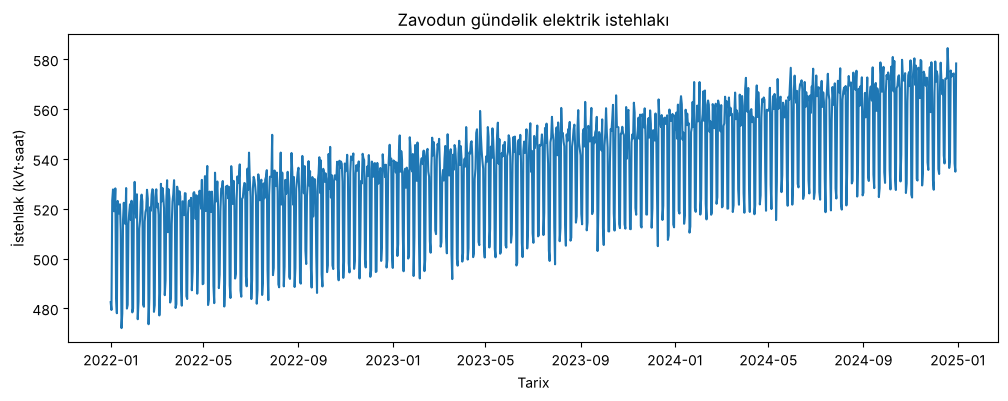

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(df["tarix"], df["istehlak"])
plt.title("Zavodun gündəlik elektrik istehlakı")
plt.xlabel("Tarix")
plt.ylabel("İstehlak (kVt·saat)")
plt.show()

## 3. Datanın train / test hissələrə bölünməsi və normallaşdırma
Zaman sırası olduğu üçün data qarışdırılmır: ilk 80% – train, son 20% – test.
Scaler yalnız train üzərində öyrədilir.

In [4]:
deyerler = df[["istehlak"]].values

bolgu = int(len(deyerler) * 0.8)
train, test = deyerler[:bolgu], deyerler[bolgu:]

scaler = MinMaxScaler()
train_sc = scaler.fit_transform(train)
test_sc = scaler.transform(test)

print("Train:", train.shape, " Test:", test.shape)

Train: (876, 1)  Test: (219, 1)


## 4. RNN üçün giriş-çıxış yaradılması
Model əvvəlki **14 günə** baxıb növbəti günün istehlakını proqnozlaşdırır.

In [5]:
pencere = 14

def pencere_yarat(data, pencere):
    X, y = [], []
    for i in range(len(data) - pencere):
        X.append(data[i:i + pencere])
        y.append(data[i + pencere])
    return np.array(X), np.array(y)

X_train, y_train = pencere_yarat(train_sc, pencere)
# test üçün əvvəlki 14 gün train-in sonundan götürülür
test_tam = np.concatenate([train_sc[-pencere:], test_sc])
X_test, y_test = pencere_yarat(test_tam, pencere)

print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (862, 14, 1)  X_test: (219, 14, 1)


## 5. RNN modelinin qurulması

In [6]:
model = Sequential([
    SimpleRNN(32, input_shape=(pencere, 1)),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Modelin öyrədilməsi

In [7]:
tarix_loss = model.fit(X_train, y_train,
                       epochs=30, batch_size=32,
                       validation_split=0.1, verbose=1)

Epoch 1/30


 1/25 ━━━━━━━━━━━━━━━━━━━━ 21s 886ms/step - loss: 0.5974

22/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1188   

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1105 - val_loss: 0.0845


Epoch 2/30


 1/25 ━━━━━━━━━━━━━━━━━━━━ 8s 340ms/step - loss: 0.0299

... (96 outputs left out)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0036 - val_loss: 0.0043


Epoch 30/30


 1/25 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0030

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0036 - val_loss: 0.0034


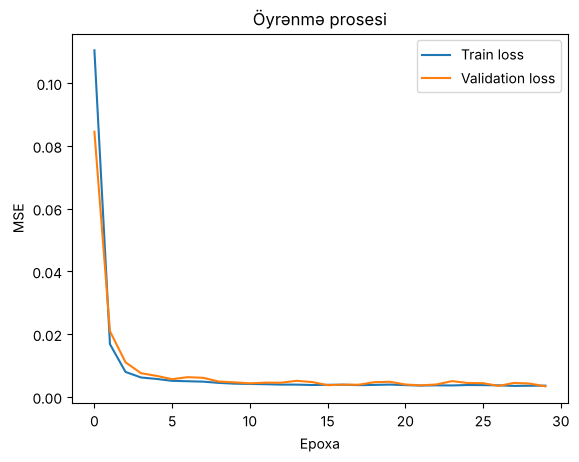

In [8]:
plt.plot(tarix_loss.history["loss"], label="Train loss")
plt.plot(tarix_loss.history["val_loss"], label="Validation loss")
plt.title("Öyrənmə prosesi")
plt.xlabel("Epoxa")
plt.ylabel("MSE")
plt.legend()
plt.show()

## 7. Proqnoz və qiymətləndirmə

In [9]:
pred_sc = model.predict(X_test)

# Orijinal miqyasa qaytarırıq
pred = scaler.inverse_transform(pred_sc)
real = scaler.inverse_transform(y_test)

mae = mean_absolute_error(real, pred)
rmse = np.sqrt(mean_squared_error(real, pred))
print(f"MAE : {mae:.2f} kVt·saat")
print(f"RMSE: {rmse:.2f} kVt·saat")

1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


MAE : 6.44 kVt·saat
RMSE: 7.74 kVt·saat


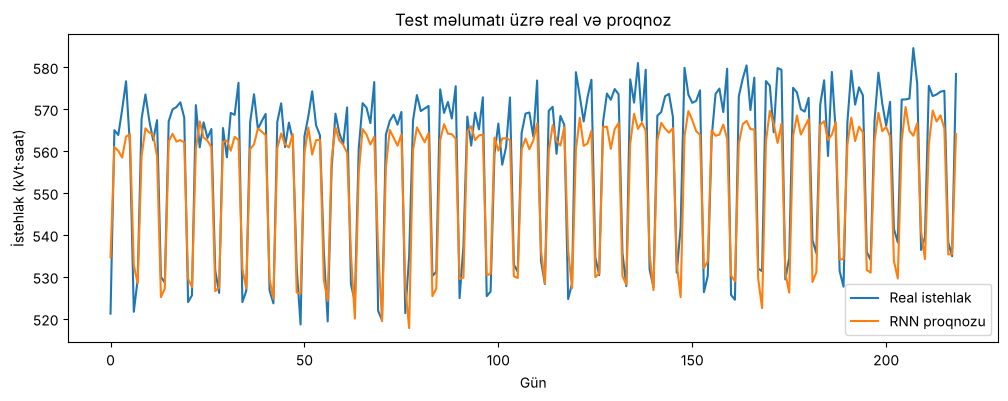

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(real, label="Real istehlak")
plt.plot(pred, label="RNN proqnozu")
plt.title("Test məlumatı üzrə real və proqnoz")
plt.xlabel("Gün")
plt.ylabel("İstehlak (kVt·saat)")
plt.legend()
plt.show()

## 8. Nəticə
- İstehsalatın gündəlik istehlak göstəricisi sadə RNN modeli ilə proqnozlaşdırıldı.
- Model əvvəlki 14 günün məlumatına əsasən növbəti günün istehlakını proqnozlaşdırır.
- Qrafikdə proqnoz xəttinin real xəttə yaxın olduğu görünür; xəta MAE və RMSE ilə ölçüldü.
- Daha yaxşı nəticə üçün LSTM, daha çox epoxa və ya əlavə göstəricilər (temperatur, istehsal həcmi) istifadə edilə bilər.